<a href="https://colab.research.google.com/github/Zafeerxyz/Machine-Learning-algorithms/blob/main/GMM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import kagglehub
path = kagglehub.dataset_download("vjchoudhary7/customer-segmentation-tutorial-in-python")

Using Colab cache for faster access to the 'customer-segmentation-tutorial-in-python' dataset.


In [ ]:
import pandas as pd
import numpy as np

In [ ]:
import pandas as pd

# Load the dataset (replace 'Mall_Customers.csv' with your actual file name)
df = pd.read_csv(f"{path}/Mall_Customers.csv")

# Display the first few rows
df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [ ]:
from sklearn.preprocessing import StandardScaler


X = df[['Annual Income (k$)', 'Spending Score (1-100)']]

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

In [ ]:
from sklearn.mixture import GaussianMixture


gmm = GaussianMixture(
    n_components=5,
    covariance_type="full",
    random_state=42
)

gmm.fit(X_scaled)

gmm_labels = gmm.predict(X_scaled)

probabilities = gmm.predict_proba(X_scaled)

In [ ]:
print(probabilities[:5])

[[1.57689698e-05 1.88009163e-08 9.52031247e-04 5.20013085e-08
  9.99032129e-01]
 [1.62776204e-05 1.89596786e-04 9.99790184e-01 4.21013390e-23
  3.94154449e-06]
 [2.21339374e-19 9.52615737e-19 1.22549539e-12 1.86223280e-04
  9.99813777e-01]
 [1.05444778e-04 1.80087695e-04 9.99693745e-01 3.79390067e-21
  2.07229768e-05]
 [6.47301428e-05 3.84273231e-08 1.55669540e-03 4.75722704e-08
  9.98378488e-01]]


In [ ]:
aic_scores = []
bic_scores = []

for k in range(2, 11):

    model = GaussianMixture(
        n_components=k,
        covariance_type="full",
        random_state=42
    )

    model.fit(X_scaled)

    aic_scores.append(model.aic(X_scaled))
    bic_scores.append(model.bic(X_scaled))

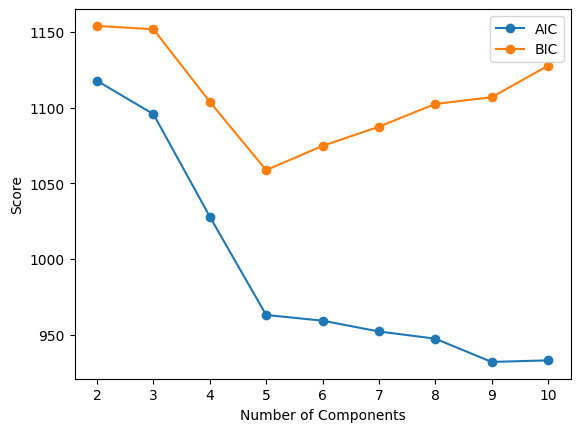

In [ ]:
import matplotlib.pyplot as plt

plt.plot(range(2, 11), aic_scores, marker="o", label="AIC")
plt.plot(range(2, 11), bic_scores, marker="o", label="BIC")

plt.xlabel("Number of Components")
plt.ylabel("Score")
plt.legend()
plt.show()

In [ ]:
import pandas as pd

cluster_sizes = pd.Series(gmm_labels).value_counts().sort_index()
print(cluster_sizes)

0    84
1    39
2    21
3    33
4    23
Name: count, dtype: int64


In [ ]:
print("Best AIC:", min(aic_scores))
print("Best BIC:", min(bic_scores))

# print("AIC components:", best_aic_k)
# print("BIC components:", best_bic_k)

Best AIC: 931.9950051849718
Best BIC: 1058.6522524191894
